<a href="https://colab.research.google.com/github/emmanuelnkemka/hospital-readmission-prediction/blob/main/module_08_deep_learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [116]:
import tensorflow as tf
print(tf.__version__)
print(tf.config.list_physical_devices('GPU'))

2.21.0
[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [117]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
%matplotlib inline

In [118]:
import tensorflow as tf
from tensorflow import keras

In [119]:
!git clone https://github.com/alexeygrigorev/clothing-dataset-small.git

fatal: destination path 'clothing-dataset-small' already exists and is not an empty directory.


In [120]:
from tensorflow.keras.preprocessing.image import load_img

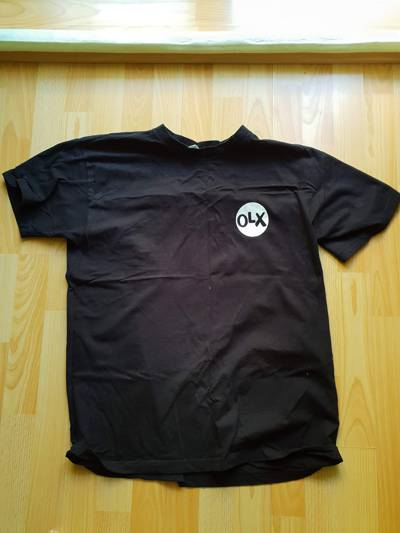

In [121]:
path = './clothing-dataset-small/train/t-shirt'
name = '5f0a3fa0-6a3d-4b68-b213-72766a643de7.jpg'
fullname = path + '/' + name
load_img(fullname)

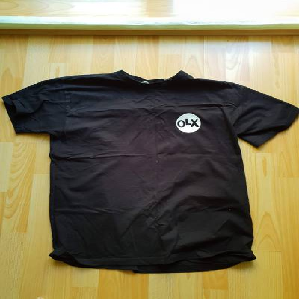

In [122]:
load_img(fullname, target_size=(299, 299))

In [123]:
img = load_img(fullname, target_size=(299, 299))

In [124]:
x = np.array(img)
x.shape

(299, 299, 3)

In [125]:
from tensorflow.keras.applications.xception import Xception
from tensorflow.keras.applications.xception import preprocess_input
from tensorflow.keras.applications.xception import decode_predictions

In [126]:
model = Xception(weights='imagenet', input_shape=(299, 299, 3))

In [127]:
X = np.array([x])

In [128]:
 X.shape

(1, 299, 299, 3)

In [129]:
pred = model.predict(X)

1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step


In [130]:
decode_predictions(pred)

[[('n03775546', 'mixing_bowl', np.float32(0.9950388)),
  ('n03942813', 'ping-pong_ball', np.float32(0.0049611335)),
  ('n04116512', 'rubber_eraser', np.float32(6.930562e-22)),
  ('n04380533', 'table_lamp', np.float32(3.7471085e-23)),
  ('n03445777', 'golf_ball', np.float32(1.02995084e-23))]]

In [131]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

In [132]:
image_size = (150, 150)
batch_size = 32

In [133]:
train_gen = ImageDataGenerator(preprocessing_function=preprocess_input)

train_ds = train_gen.flow_from_directory('clothing-dataset-small/train', seed=1,
    target_size=(150, 150),
    batch_size=32
)

Found 3068 images belonging to 10 classes.


In [134]:
train_ds.class_indices

{'dress': 0,
 'hat': 1,
 'longsleeve': 2,
 'outwear': 3,
 'pants': 4,
 'shirt': 5,
 'shoes': 6,
 'shorts': 7,
 'skirt': 8,
 't-shirt': 9}

In [135]:
X, y = next(train_ds)

In [136]:
y[:5]

array([[0., 0., 0., 1., 0., 0., 0., 0., 0., 0.],
       [1., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 1.],
       [1., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 1., 0., 0., 0.]], dtype=float32)

In [137]:
val_gen = ImageDataGenerator(preprocessing_function=preprocess_input)

val_ds = train_gen.flow_from_directory(
    './clothing-dataset-small/validation',
    target_size=(150, 150),
    batch_size=32,
    shuffle=False
)

Found 341 images belonging to 10 classes.


In [138]:
# Import and instantiate Xception consistently from the standalone keras API to match the input
from keras.applications.xception import Xception
from keras.applications.xception import preprocess_input

base_model = Xception(
    weights='imagenet',
    include_top=False,
    input_shape=(150, 150, 3)
)

base_model.trainable = False

In [142]:
# Define the model using the matched standalone Keras API
inputs = keras.Input(shape=(150, 150, 3))

base = base_model(inputs)

vectors = keras.layers.GlobalAveragePooling2D()(base)

outputs = keras.layers.Dense(10)(vectors)

model = keras.Model(inputs, outputs)

In [143]:
preds = model.predict(X)

1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step


In [144]:
preds.shape

(32, 10)

In [146]:
pred = model.predict(X)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 117ms/step


In [148]:
preds[0]

array([-0.24799383,  0.9174447 ,  0.02757126,  0.15925688,  0.12936181,
        0.32671827, -0.9020072 , -0.89753586,  0.09965675,  0.31784716],
      dtype=float32)

In [ ]:
learning_rate = 0.001
optimizers = keras.optimizers.Adam(learning_rate=learning_rate)

keras.losses = keras.losses.CategoricalCrossentropy(from_logits=True)